In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from scipy.stats import kurtosis, skew
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train_dir = '/content/drive/MyDrive/datasets/train-emotions'
test_dir = '/content/drive/MyDrive/datasets/test-emotions'

In [ ]:
def load_raw_images(folder_path):
    images = []
    labels = []
    emotion_folders = {'angry': 0, 'happy': 1}  # Definir las etiquetas para las carpetas

    for emotion, label in emotion_folders.items():
        emotion_folder = os.path.join(folder_path, emotion)
        for filename in os.listdir(emotion_folder):
            if filename.endswith('.jpg'):
                image_path = os.path.join(emotion_folder, filename)
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
                images.append(image)
                labels.append(label)
    return images, labels

train_images_raw, train_labels_raw = load_raw_images(train_dir)
test_images_raw, test_labels_raw = load_raw_images(test_dir)

In [ ]:
# Verificar el tamaño de las imágenes
for idx, image in enumerate(train_images_raw):
    print(f"Imagen {idx} tiene dimensiones: {image.shape}")

Streaming output truncated to the last 5000 lines.
Imagen 5700 tiene dimensiones: (48, 48)
Imagen 5701 tiene dimensiones: (48, 48)
Imagen 5702 tiene dimensiones: (48, 48)
Imagen 5703 tiene dimensiones: (48, 48)
Imagen 5704 tiene dimensiones: (48, 48)
Imagen 5705 tiene dimensiones: (48, 48)
Imagen 5706 tiene dimensiones: (48, 48)
Imagen 5707 tiene dimensiones: (48, 48)
Imagen 5708 tiene dimensiones: (48, 48)
Imagen 5709 tiene dimensiones: (48, 48)
Imagen 5710 tiene dimensiones: (48, 48)
Imagen 5711 tiene dimensiones: (48, 48)
Imagen 5712 tiene dimensiones: (48, 48)
Imagen 5713 tiene dimensiones: (48, 48)
Imagen 5714 tiene dimensiones: (48, 48)
Imagen 5715 tiene dimensiones: (48, 48)
Imagen 5716 tiene dimensiones: (48, 48)
Imagen 5717 tiene dimensiones: (48, 48)
Imagen 5718 tiene dimensiones: (48, 48)
Imagen 5719 tiene dimensiones: (48, 48)
Imagen 5720 tiene dimensiones: (48, 48)
Imagen 5721 tiene dimensiones: (48, 48)
Imagen 5722 tiene dimensiones: (48, 48)
Imagen 5723 tiene dimensiones

In [ ]:
# Contar la cantidad total de imágenes
print(f"Cantidad total de imágenes en train: {len(train_images_raw)}")
print(f"Cantidad total de imágenes en test: {len(test_images_raw)}")

Cantidad total de imágenes en train: 10700
Cantidad total de imágenes en test: 2732


In [ ]:
from collections import Counter
emotion_count_raw = Counter(train_labels_raw)
print(f"Cantidad de imágenes por emoción en train: {emotion_count_raw}")

Cantidad de imágenes por emoción en train: Counter({1: 7215, 0: 3485})


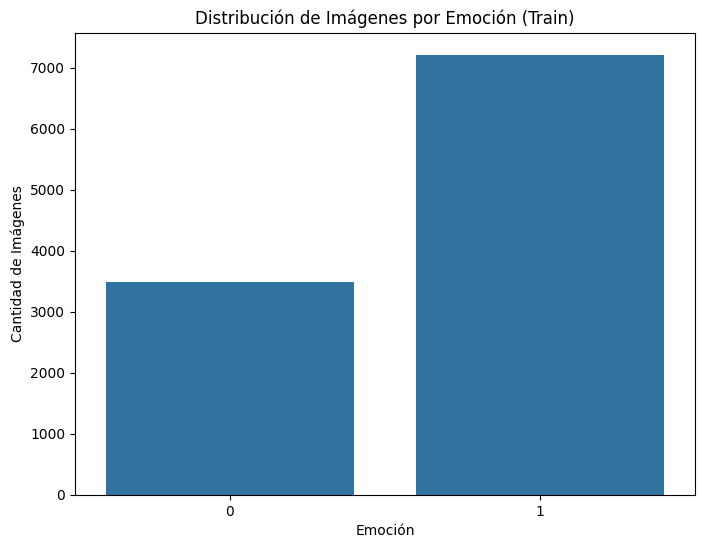

In [ ]:
# prompt: grafico de la cantidad de imagenes por emocion

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.countplot(x=train_labels_raw)
plt.title('Distribución de Imágenes por Emoción (Train)')
plt.xlabel('Emoción')
plt.ylabel('Cantidad de Imágenes')
plt.show()

In [ ]:
for idx, image in enumerate(train_images_raw):
    if np.var(image) < 0.01:
        print(f"Imagen {idx} es casi negra.")

Imagen 524 es casi negra.
Imagen 1417 es casi negra.
Imagen 2364 es casi negra.
Imagen 2523 es casi negra.
Imagen 3016 es casi negra.
Imagen 3499 es casi negra.


In [ ]:
def analyze_raw_images(images):
    for idx, image in enumerate(images):
        stats = calculate_statistics(image)  # Calcular estadísticas
        print(f"Estadísticas para la imagen {idx}: Media: {stats[0]:.2f}, Varianza: {stats[1]:.2f}, Curtosis: {stats[2]:.2f}, Asimetría: {stats[3]:.2f}")

        # visualizar la imagen y las estadísticas
        # plt.imshow(image, cmap='gray')
        # plt.title(f"Imagen {idx} - Media: {stats[0]:.2f}")
        # plt.axis('off')
        # plt.show()


In [ ]:
# Llamar a la función para analizar imágenes crudas
analyze_raw_images(train_images_raw)

Streaming output truncated to the last 5000 lines.
Estadísticas para la imagen 5700: Media: 107.01, Varianza: 2618.03, Curtosis: -1.00, Asimetría: 0.14
Estadísticas para la imagen 5701: Media: 182.05, Varianza: 3003.53, Curtosis: -0.99, Asimetría: -0.41
Estadísticas para la imagen 5702: Media: 108.62, Varianza: 4052.09, Curtosis: -1.52, Asimetría: 0.06
Estadísticas para la imagen 5703: Media: 112.33, Varianza: 2744.71, Curtosis: -0.87, Asimetría: -0.54
Estadísticas para la imagen 5704: Media: 129.01, Varianza: 6588.45, Curtosis: -1.24, Asimetría: -0.37
Estadísticas para la imagen 5705: Media: 100.53, Varianza: 3264.50, Curtosis: -0.64, Asimetría: 0.04
Estadísticas para la imagen 5706: Media: 164.04, Varianza: 2365.67, Curtosis: 1.04, Asimetría: -1.02
Estadísticas para la imagen 5707: Media: 152.32, Varianza: 2430.25, Curtosis: 0.15, Asimetría: -0.60
Estadísticas para la imagen 5708: Media: 148.93, Varianza: 1795.41, Curtosis: 1.16, Asimetría: -1.14
Estadísticas para la imagen 5709: Med

### no comentado

In [ ]:
def normalize_image(image):
    min_val = np.min(image)
    max_val = np.max(image)
    if max_val - min_val == 0:
        return image  # Si la imagen es constante, devolver la misma
    else:
        return (image - min_val) / (max_val - min_val)

def calculate_statistics(image):
    mean_val = np.mean(image)
    var_val = np.var(image)
    kurt_val = kurtosis(image, axis=None)  # Curtosis sobre todos los píxeles
    skew_val = skew(image, axis=None)  # Asimetría sobre todos los píxeles
    return mean_val, var_val, kurt_val, skew_val

def preprocess_image(image):
    # Normalizar la imagen primero
    image_normalized = normalize_image(image)
    image_normalized = np.float32(image_normalized) #es necesario convertirlo a

    # Aplicar filtro bilateral para suavizado
    image_bilateral = cv2.bilateralFilter(image_normalized, 9, 75, 75)

    # Detección de bordes con Sobel (derivadas en x e y)
    sobelx = cv2.Sobel(image_normalized, cv2.CV_64F, 1, 0, ksize=5)
    sobely = cv2.Sobel(image_normalized, cv2.CV_64F, 0, 1, ksize=5)
    image_edges = cv2.magnitude(sobelx, sobely)  # Magnitud de los bordes

    # Calcular estadísticas para ambos filtros
    bilateral_stats = calculate_statistics(image_bilateral)
    sobel_stats = calculate_statistics(image_edges)

    # Retornar todas las estadísticas como características
    features = np.hstack((bilateral_stats, sobel_stats))  # Concatenar todas las características
    return features

# Función para preprocesar las imágenes de una carpeta
def preprocess_images_in_folder(folder_path, max_images_per_folder=50):
    features = []
    labels = []

    # Definir las etiquetas para las carpetas
    emotion_folders = {'angry': 0, 'happy': 1}

    # Recorrer las carpetas de emociones
    for emotion, label in emotion_folders.items():
        emotion_folder = os.path.join(folder_path, emotion)

        print(f"Procesando carpeta: {emotion_folder}")
        if not os.path.exists(emotion_folder):
            print(f"Carpeta {emotion_folder} no encontrada")
            continue

        count = 0
        for filename in os.listdir(emotion_folder):
            if filename.endswith('.jpg'):
                image_path = os.path.join(emotion_folder, filename)
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                # Aplicar preprocesamiento y obtener características
                image_features = preprocess_image(image)

                features.append(image_features)
                labels.append(label)

                count += 1

                # Detenerse después de procesar el número máximo de imágenes
                if count >= max_images_per_folder:
                    break

        print(f"Total de imágenes procesadas para {emotion}: {count}")

    return features, labels

# Procesar imágenes de entrenamiento y prueba
train_features, train_labels = preprocess_images_in_folder(train_dir, max_images_per_folder=50)
test_features, test_labels = preprocess_images_in_folder(test_dir, max_images_per_folder=50)

print("\n")
print(f"Número de imágenes procesadas en train: {len(train_features)}")
print(f"Número de imágenes procesadas en test: {len(test_features)}")



Procesando carpeta: /content/drive/MyDrive/datasets/train-emotions/angry
Total de imágenes procesadas para angry: 50
Procesando carpeta: /content/drive/MyDrive/datasets/train-emotions/happy
Total de imágenes procesadas para happy: 50
Procesando carpeta: /content/drive/MyDrive/datasets/test-emotions/angry
Total de imágenes procesadas para angry: 50
Procesando carpeta: /content/drive/MyDrive/datasets/test-emotions/happy
Total de imágenes procesadas para happy: 50


Número de imágenes procesadas en train: 100
Número de imágenes procesadas en test: 100


In [ ]:
train_features[0]

array([ 5.02236068e-01,  6.97908849e-02, -1.69603437e+00,  1.73415698e-02,
        5.38074904e+00,  3.28636417e+01,  2.37247505e+00,  1.62274268e+00])

In [ ]:
# Función para guardar imágenes y etiquetas preprocesadas
def save_preprocessed_data(images, labels, prefix='train'):
    # Convertir a arrays de NumPy si no lo son ya
    images_array = np.array(images)
    labels_array = np.array(labels)

    # Guardar las imágenes y las etiquetas como archivos .npy
    np.save(f'{prefix}_images.npy', images_array)
    np.save(f'{prefix}_labels.npy', labels_array)

# Después de haber procesado las imágenes
train_images, train_labels = preprocess_images_in_folder(train_dir)
test_images, test_labels = preprocess_images_in_folder(test_dir)

# Guardar las imágenes preprocesadas de train y test
save_preprocessed_data(train_images, train_labels, prefix='train')
save_preprocessed_data(test_images, test_labels, prefix='test')

print("Imágenes y etiquetas preprocesadas guardadas correctamente.")



# Función para cargar imágenes y etiquetas preprocesadas
def load_preprocessed_data(prefix='train'):
    images = np.load(f'{prefix}_images.npy')
    labels = np.load(f'{prefix}_labels.npy')
    return images, labels

# Cargar imágenes preprocesadas de train y test
train_images, train_labels = load_preprocessed_data(prefix='train')
test_images, test_labels = load_preprocessed_data(prefix='test')

print("Imágenes y etiquetas preprocesadas cargadas correctamente.")

Procesando carpeta: /content/drive/MyDrive/datasets/train-emotions/angry
Total de imágenes procesadas para angry: 50
Procesando carpeta: /content/drive/MyDrive/datasets/train-emotions/happy
Total de imágenes procesadas para happy: 50
Procesando carpeta: /content/drive/MyDrive/datasets/test-emotions/angry
Total de imágenes procesadas para angry: 50
Procesando carpeta: /content/drive/MyDrive/datasets/test-emotions/happy
Total de imágenes procesadas para happy: 50
Imágenes y etiquetas preprocesadas guardadas correctamente.
Imágenes y etiquetas preprocesadas cargadas correctamente.


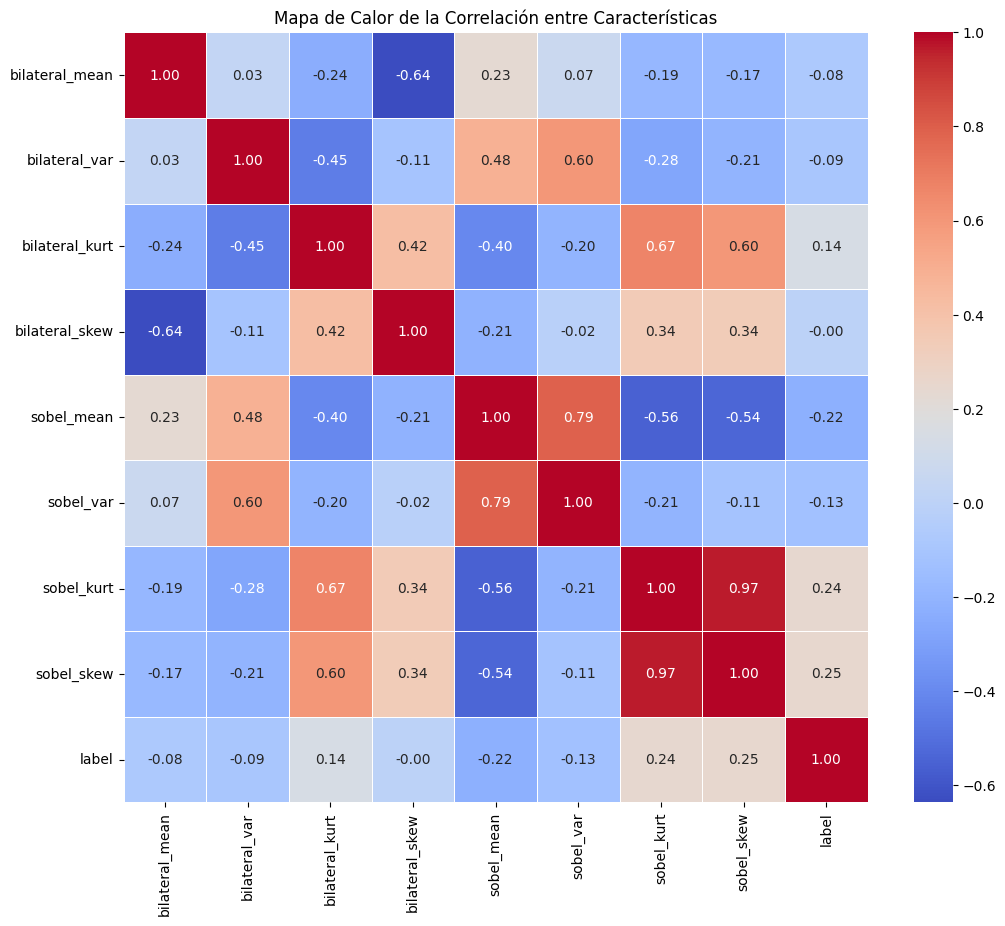

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convertir las características y etiquetas en un DataFrame
df_features = pd.DataFrame(train_features, columns=[
    'bilateral_mean', 'bilateral_var', 'bilateral_kurt', 'bilateral_skew',
    'sobel_mean', 'sobel_var', 'sobel_kurt', 'sobel_skew'
])

# Agregar las etiquetas al DataFrame
df_features['label'] = train_labels

# Calcular la matriz de correlación entre las características
correlation_matrix = df_features.corr()

# Crear el mapa de calor
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Mapa de Calor de la Correlación entre Características')
plt.show()
